# HW3 · Notebook 3: ансамбль, зсув класів під macro-F1, стекінг

Працює тільки з ймовірностями, збереженими в Notebook 1 і 2, тому GPU не потрібен (хвилини на CPU).
Inputs: змагання + `hw3-01-eda-baseline` + ймовірності XLM-R. Ця версія використовує `hw3-02-xlmr` (XLM-R 32k); фінальна модель --- у `hw3-03-ensemble` (на `hw3-02b-xlmr-80k`).

Експерименти (усі порівнюються з фіксованим референсом, XLM-R на тому самому val):
1. **Зважений ансамбль** TF-IDF + XLM-R.
2. **Зсув класів (class bias)** під macro-F1.
3. **Стекінг**: логістична регресія поверх ймовірностей обох моделей + статистик по чанках + довжини.

Щоб не обманювати себе: все, що підбирається на val, оцінюємо **чесно**, через cross-fitting
(підбираємо на одній половині val, міряємо на іншій, і навпаки).

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

SEED = 42
LABELS = ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    p = glob.glob(f'/kaggle/input/**/{name}', recursive=True) or glob.glob(f'out/{name}')
    return p[0] if p else None

DATA_DIR = os.path.dirname(find('train.csv') or 'data/train.csv')
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else 'out'
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
sample_sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')

# val у тому самому порядку, в якому збережені ймовірності; перевіряємо, що обидва ноутбуки мають однаковий val
val_ids = pd.read_csv(find('val_ids.csv'))['id']
split = pd.read_csv(find('split.csv'))
assert (split.loc[split.split == 'val', 'id'].values == val_ids.values).all(), 'Порядок val не збігається!'
val = val_ids.to_frame().merge(train, on='id', how='left')
y_val = val['label'].map(L2I).values

load = lambda n: np.load(find(n))
P_val = {'tfidf': load('tfidf_lr_val_proba.npy')}
P_test = {'tfidf': load('tfidf_lr_test_proba.npy')}
for k in ['head', 'headtail', 'chunks', 'chunkmax']:
    P_val[f'xlmr_{k}'] = load(f'xlmr_{k}_val_proba.npy')
    P_test[f'xlmr_{k}'] = load(f'xlmr_{k}_test_proba.npy')
assert all(len(p) == len(test) for p in P_test.values())

f1 = lambda y, pred: f1_score(y, pred, average='macro')
print('val:', len(y_val), '| test:', len(test))

val: 8000 | test: 25000


## 1. Окремі моделі на фіксованому val

In [2]:
single = pd.DataFrame([{'model': k, 'macro_f1': f1(y_val, p.argmax(1))}
                       for k, p in P_val.items() if k != 'xlmr_chunkmax']).round(4)
REF = single[single.model.str.startswith('xlmr')].sort_values('macro_f1').iloc[-1]['model']
print('Референс (найкращий XLM-R):', REF)
single.sort_values('macro_f1', ascending=False)

Референс (найкращий XLM-R): xlmr_chunks


,model,macro_f1
3,xlmr_chunks,0.8837
2,xlmr_headtail,0.8758
1,xlmr_head,0.8464
0,tfidf,0.8423


## 2. Зважений ансамбль TF-IDF + XLM-R

`p = w · p_xlmr + (1 − w) · p_tfidf`. Моделі різні за природою: TF-IDF бачить увесь текст як мішок n-грам
(включно з типографікою), трансформер бачить контекст, але тільки 512 токенів за раз.
Якщо вони помиляються на різних текстах, середнє виправляє частину помилок.

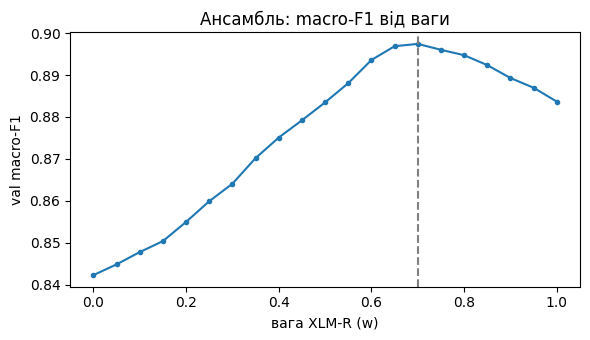

w = 0.7: macro-F1 0.8974 (w=0 це TF-IDF, w=1 це XLM-R)


In [3]:
W = np.round(np.arange(0, 1.01, 0.05), 2)
blend = lambda Px, Pt, w: w * Px + (1 - w) * Pt
curve = [f1(y_val, blend(P_val[REF], P_val['tfidf'], w).argmax(1)) for w in W]
w_best = W[int(np.argmax(curve))]

plt.figure(figsize=(6, 3.5))
plt.plot(W, curve, marker='o', ms=3)
plt.axvline(w_best, ls='--', c='gray')
plt.xlabel('вага XLM-R (w)'); plt.ylabel('val macro-F1'); plt.title('Ансамбль: macro-F1 від ваги')
plt.tight_layout(); plt.show()
print(f'w = {w_best}: macro-F1 {max(curve):.4f} (w=0 це TF-IDF, w=1 це XLM-R)')

## 3. Зсув класів під macro-F1

argmax ймовірностей максимізує accuracy, а не macro-F1. Macro-F1 рахує human і fusion нарівні з
великим класом ai, тому вигідно трохи зсунути межу між human і fusion.
Додаємо до log-ймовірностей зсув `b_human` і `b_fusion` (ai = 0) і шукаємо їх по сітці.

Чесна оцінка: ділимо val навпіл, підбираємо (w, зсуви) на одній половині, міряємо на іншій, і навпаки.

In [4]:
GRID = np.round(np.arange(-1.5, 1.51, 0.1), 2)

def predict_bias(P, b):
    return (np.log(np.clip(P, 1e-9, 1)) + b).argmax(1)

def tune_bias(P, y):
    best_f, best_b = -1, np.zeros(3)
    for bh in GRID:
        for bf in GRID:
            b = np.array([bh, 0.0, bf])
            s = f1(y, predict_bias(P, b))
            if s > best_f:
                best_f, best_b = s, b
    return best_b

def tune_all(idx):
    # на підмножині idx підбираємо вагу ансамблю, потім зсуви
    w = W[int(np.argmax([f1(y_val[idx], blend(P_val[REF][idx], P_val['tfidf'][idx], w).argmax(1)) for w in W]))]
    b = tune_bias(blend(P_val[REF][idx], P_val['tfidf'][idx], w), y_val[idx])
    return w, b

def cross_fit(method):
    # повертає чесні out-of-fold передбачення на val
    pred = np.empty(len(y_val), dtype=int)
    for a, b in StratifiedKFold(2, shuffle=True, random_state=SEED).split(y_val, y_val):
        pred[b] = method(a, b)
    return pred

honest = {}
honest['XLM-R + bias'] = cross_fit(lambda a, b: predict_bias(P_val[REF][b], tune_bias(P_val[REF][a], y_val[a])))
honest['ensemble (w)'] = cross_fit(lambda a, b: blend(P_val[REF][b], P_val['tfidf'][b], tune_all(a)[0]).argmax(1))
def ens_bias(a, b):
    w, bias = tune_all(a)
    return predict_bias(blend(P_val[REF][b], P_val['tfidf'][b], w), bias)
honest['ensemble (w) + bias'] = cross_fit(ens_bias)

w_full, b_full = tune_all(np.arange(len(y_val)))
print('На всьому val: w =', w_full, '| зсуви (human, ai, fusion) =', b_full)
{k: round(f1(y_val, p), 4) for k, p in honest.items()}

На всьому val: w = 0.7 | зсуви (human, ai, fusion) = [0.7 0.  0.6]


{'XLM-R + bias': 0.888, 'ensemble (w)': 0.8966, 'ensemble (w) + bias': 0.9001}

## 4. Стекінг

Мета-модель (логістична регресія) вчиться на val поверх ознак, яких базові моделі не бачили разом:
ймовірності TF-IDF, XLM-R (head+tail і середнє по чанках), **максимум по чанках** і довжина тексту.

Чому максимум по чанках: fusion — це людський текст, де LLM переписала частину. Тому в fusion-тексті
очікуємо, що *хоча б один* чанк виглядає як ai, навіть якщо в середньому текст людський.
Для чесної оцінки використовуємо 5-fold cross_val_predict на val.

In [5]:
def stack_features(P, texts):
    lg = lambda x: np.log(np.clip(x, 1e-6, 1))
    return np.hstack([lg(P['tfidf']), lg(P['xlmr_headtail']), lg(P['xlmr_chunks']), lg(P['xlmr_chunkmax']),
                      np.log1p(texts.str.len().values)[:, None]])

X_val_st = stack_features(P_val, val['text'])
X_test_st = stack_features(P_test, test['text'])
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for cw in [None, 'balanced']:
    meta = LogisticRegression(C=1.0, max_iter=3000, class_weight=cw)
    oof = cross_val_predict(meta, X_val_st, y_val, cv=skf)
    honest[f'stacking (class_weight={cw})'] = oof
    print(cw, round(f1(y_val, oof), 4))

None 0.91
balanced 0.9091


### 4b. Абляція стекінгу: що саме дає приріст

Прибираємо з мета-моделі по одній групі ознак і дивимось, наскільки падає чесна (5-fold) оцінка.
Чим більше падіння, тим сильніше модель спирається на цю групу.

In [6]:
groups = {'tfidf': range(0, 3), 'xlmr_headtail': range(3, 6), 'xlmr_chunks (mean)': range(6, 9),
          'xlmr_chunkmax': range(9, 12), 'length': range(12, 13)}
full = f1(y_val, honest['stacking (class_weight=None)'])
abl = []
for name, cols in groups.items():
    keep = [i for i in range(X_val_st.shape[1]) if i not in cols]
    oof = cross_val_predict(LogisticRegression(C=1.0, max_iter=3000), X_val_st[:, keep], y_val, cv=skf)
    s = f1(y_val, oof)
    pc = f1_score(y_val, oof, average=None)
    abl.append({'без групи': name, 'macro_f1': round(s, 4), 'Δ': round(s - full, 4),
                'F1 human': round(pc[0], 3), 'F1 fusion': round(pc[2], 3)})
print('повний стекінг:', round(full, 4))
pd.DataFrame(abl).sort_values('Δ')

повний стекінг: 0.91


,без групи,macro_f1,Δ,F1 human,F1 fusion
1,xlmr_headtail,0.9023,-0.0077,0.849,0.869
0,tfidf,0.9027,-0.0073,0.851,0.869
3,xlmr_chunkmax,0.9074,-0.0026,0.861,0.871
4,length,0.9104,0.0004,0.864,0.877
2,xlmr_chunks (mean),0.9105,0.0005,0.865,0.877


## 5. Підсумкова таблиця (усе на тому самому val)

In [7]:
rows = [{'model': r.model, 'val_macro_f1': r.macro_f1, 'оцінка': 'без підбору на val'} for r in single.itertuples()]
rows += [{'model': k, 'val_macro_f1': round(f1(y_val, p), 4), 'оцінка': 'cross-fit (чесна)'} for k, p in honest.items()]
summary = pd.DataFrame(rows).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)
summary['Δ до референсу'] = (summary['val_macro_f1'] - single.set_index('model').loc[REF, 'macro_f1']).round(4)
summary

,model,val_macro_f1,оцінка,Δ до референсу
0,stacking (class_weight=None),0.9100,cross-fit (чесна),0.0263
1,stacking (class_weight=balanced),0.9091,cross-fit (чесна),0.0254
2,ensemble (w) + bias,0.9001,cross-fit (чесна),0.0164
3,ensemble (w),0.8966,cross-fit (чесна),0.0129
4,XLM-R + bias,0.8880,cross-fit (чесна),0.0043
5,xlmr_chunks,0.8837,без підбору на val,0.0000
6,xlmr_headtail,0.8758,без підбору на val,-0.0079
7,xlmr_head,0.8464,без підбору на val,-0.0373
8,tfidf,0.8423,без підбору на val,-0.0414


Найкращий підхід: stacking (class_weight=None)
              precision    recall  f1-score   support

       human      0.824     0.907     0.864      1960
          ai      0.989     0.991     0.990      3581
      fusion      0.916     0.840     0.877      2459

    accuracy                          0.924      8000
   macro avg      0.910     0.913     0.910      8000
weighted avg      0.926     0.924     0.924      8000



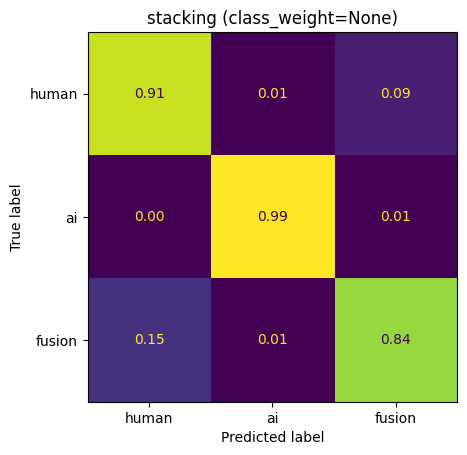

In [8]:
best_name = summary.iloc[0]['model']
pred = honest[best_name] if best_name in honest else P_val[best_name].argmax(1)
print('Найкращий підхід:', best_name)
print(classification_report(y_val, pred, target_names=LABELS, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred, normalize='true'), display_labels=LABELS).plot(
    colorbar=False, values_format='.2f')
plt.title(best_name); plt.show()

## 6. Сабміти

Фінальні моделі підбираються на **всьому** val (cross-fit був тільки для чесної оцінки).
Зберігаємо кілька варіантів; на Kaggle варто відправити найкращий за чесною оцінкою і, як другий фінальний, найкращий з іншого сімейства.

In [9]:
def save_sub(name, pred_idx):
    sub = pd.DataFrame({'id': test['id'].values, 'label': np.array(LABELS)[pred_idx]})
    sub = sample_sub[['id']].merge(sub, on='id', how='left')
    assert len(sub) == len(sample_sub) and sub['label'].notna().all() and sub['id'].is_unique
    sub.to_csv(f'{OUT_DIR}/submission_{name}.csv', index=False)
    print(f'submission_{name}.csv', sub['label'].value_counts(normalize=True).round(3).to_dict())

save_sub('ensemble_bias', predict_bias(blend(P_test[REF], P_test['tfidf'], w_full), b_full))
save_sub('ensemble', blend(P_test[REF], P_test['tfidf'], w_full).argmax(1))
cw_best = max([None, 'balanced'], key=lambda c: f1(y_val, honest[f'stacking (class_weight={c})']))
meta = LogisticRegression(C=1.0, max_iter=3000, class_weight=cw_best).fit(X_val_st, y_val)
save_sub('stacking', meta.predict(X_test_st))
print('Розподіл класів у train:', train['label'].value_counts(normalize=True).round(3).to_dict())

submission_ensemble_bias.csv {'ai': 0.513, 'human': 0.27, 'fusion': 0.217}
submission_ensemble.csv {'ai': 0.517, 'human': 0.261, 'fusion': 0.222}
submission_stacking.csv {'ai': 0.514, 'human': 0.271, 'fusion': 0.215}
Розподіл класів у train: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}
